In [1]:
from pathlib import Path
import os
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
os.environ.setdefault('KERAS_HOME', str(Path.cwd() / '.keras'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from IPython.display import display


2026-10-26 23:44:36.570974: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1793038476.630584   53552 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793038476.647529   53552 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793038476.687346   53552 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793038476.687391   53552 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793038476.687396   53552 computation_placer.cc:177] computation placer alr

In [2]:
SEED = 42
keras.utils.set_random_seed(SEED)
QUICK_RUN = False
print('TensorFlow:', tf.__version__)
print('GPUs:', tf.config.list_physical_devices('GPU'))

import re
EPOCHS = 1 if QUICK_RUN else 10
TRAIN_POOL_SIZE = 1000 if QUICK_RUN else 8000
TEST_SIZE = 250 if QUICK_RUN else 2000
MAX_TOKENS = 10000
SEQUENCE_LENGTH = 120
BATCH_SIZE = 64
CSV_PATH = Path('data/IMDB-Dataset.csv')
OUTPUT_DIR = Path('outputs/exp05')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


TensorFlow: 2.19.1
GPUs: []


E0000 00:00:1793038484.566459   53552 cuda_executor.cc:1228] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1793038484.580667   53552 gpu_device.cc:2341] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


In [3]:
def early_stopping(patience=5):
    return keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=patience,
        min_delta=1e-4,
        restore_best_weights=True,
        verbose=1,
    )


In [4]:
def sample_reviews(texts, labels, count):
    if count >= len(labels):
        return (texts, labels)
    selected, _ = train_test_split(
        np.arange(len(labels)),
        train_size=count,
        stratify=labels,
        random_state=SEED,
    )
    return (texts[selected], labels[selected])


In [5]:
def load_raw_split(directory):
    texts, labels = ([], [])
    for label, folder in enumerate(('neg', 'pos')):
        for path in sorted((directory / folder).glob('*.txt')):
            texts.append(path.read_text(encoding='utf-8'))
            labels.append(label)
    return (np.asarray(texts, dtype=object), np.asarray(labels, dtype='int32'))


def decode_reviews(sequences, index_to_word):
    reviews = []
    for sequence in sequences:
        words = [index_to_word.get(int(index), '[UNK]') for index in sequence]
        reviews.append(' '.join(words))
    return np.asarray(reviews, dtype=object)


In [6]:
def load_imdb_reviews():
    if CSV_PATH.is_file():
        frame = pd.read_csv(CSV_PATH)
        if not {'review', 'sentiment'}.issubset(frame.columns):
            raise ValueError('CSV must contain review and sentiment columns')
        frame = frame.dropna(subset=['review', 'sentiment']).copy()
        frame['sentiment'] = frame['sentiment'].astype(str).str.strip().str.lower()
        frame = frame[frame['sentiment'].isin(['negative', 'positive'])]
        frame = frame.drop_duplicates(subset='review')
        texts = frame['review'].astype(str).to_numpy(dtype=object)
        labels = (frame['sentiment'] == 'positive').to_numpy(dtype='int32')
        pool_text, test_text, pool_y, test_y = train_test_split(
            texts,
            labels,
            test_size=0.2,
            stratify=labels,
            random_state=SEED,
        )
        return pool_text, pool_y, test_text, test_y

    candidates = [Path('data/aclImdb')]
    candidates.extend(Path('data/imdb').glob('**/aclImdb'))
    for directory in candidates:
        train_dir = directory / 'train'
        test_dir = directory / 'test'
        if (train_dir / 'pos').is_dir() and (test_dir / 'pos').is_dir():
            pool_text, pool_y = load_raw_split(train_dir)
            test_text, test_y = load_raw_split(test_dir)
            return pool_text, pool_y, test_text, test_y

    print('Loading IMDB from the Keras cache or Google storage...')
    try:
        (train_sequences, pool_y), (test_sequences, test_y) = (
            keras.datasets.imdb.load_data(
                seed=SEED,
                start_char=None,
                index_from=0,
                oov_char=None,
            )
        )
        word_index = keras.datasets.imdb.get_word_index()
    except Exception as error:
        raise RuntimeError(
            'Could not load IMDB from Google storage. For offline use, place '
            'IMDB-Dataset.csv in data/ with review and sentiment columns, or '
            'copy imdb.npz and imdb_word_index.json into .keras/datasets/.'
        ) from error

    index_to_word = {index: word for word, index in word_index.items()}
    pool_text = decode_reviews(train_sequences, index_to_word)
    test_text = decode_reviews(test_sequences, index_to_word)
    return pool_text, pool_y, test_text, test_y


In [7]:
pool_text, pool_y, test_text, test_y = load_imdb_reviews()
pool_text, pool_y = sample_reviews(pool_text, pool_y, TRAIN_POOL_SIZE)
test_text, test_y = sample_reviews(test_text, test_y, TEST_SIZE)
train_text, val_text, train_y, val_y = train_test_split(
    pool_text,
    pool_y,
    test_size=0.15,
    stratify=pool_y,
    random_state=SEED,
)
print('Train:', len(train_text), 'Validation:', len(val_text), 'Test:', len(test_text))

Loading IMDB from the Keras cache or Google storage...
17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train: 6800 Validation: 1200 Test: 2000


In [8]:
@keras.utils.register_keras_serializable(package='DLExperiment')
def clean_text(text):
    text = tf.strings.regex_replace(tf.strings.lower(text), '<br\\s*/?>', ' ')
    return tf.strings.regex_replace(text, "[^a-z0-9' ]", ' ')


In [9]:
vectorizer = layers.TextVectorization(
    max_tokens=MAX_TOKENS,
    output_mode='int',
    output_sequence_length=SEQUENCE_LENGTH,
    standardize=clean_text,
)
vectorizer.adapt(
    tf.data.Dataset.from_tensor_slices(tf.constant(train_text.tolist())).batch(256),
)
print('Vocabulary size:', vectorizer.vocabulary_size())
print('Sample vocabulary:', vectorizer.get_vocabulary()[:15])
print(
    'Vectorized sample:',
    vectorizer(tf.constant(train_text[:1].tolist())).numpy()[0, :30],
)
inputs = keras.Input(shape=(), dtype=tf.string, name='review')
x = vectorizer(inputs)
x = layers.Embedding(vectorizer.vocabulary_size(), 32, mask_zero=True)(x)
x = layers.Bidirectional(layers.LSTM(32, return_sequences=True))(x)
x = layers.Bidirectional(layers.LSTM(16))(x)
x = layers.Dense(64, activation='relu')(x)
x = layers.Dropout(0.5)(x)
model = keras.Model(
    inputs,
    layers.Dense(1, activation='sigmoid')(x),
    name='imdb_bilstm',
)
model.compile(
    optimizer=keras.optimizers.Adam(0.001),
    loss='binary_crossentropy',
    metrics=['accuracy'],
)
model.summary()


Vocabulary size: 10000
Sample vocabulary: ['', '[UNK]', np.str_('the'), np.str_('and'), np.str_('a'), np.str_('of'), np.str_('to'), np.str_('is'), np.str_('br'), np.str_('in'), np.str_('it'), np.str_('i'), np.str_('this'), np.str_('that'), np.str_('as')]
Vectorized sample: [ 264    1   12 4535   18   11   78  975   13   10    7    4   51  550
  981    5    2   61   72  898 2248  244   10    7   36 4535    3   45
   45   79]


Model: "imdb_bilstm"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ review (InputLayer) │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization  │ (None, 120)       │          0 │ review[0][0]      │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 120, 32)   │    320,000 │ text_vectorizati… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 120)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional       │ (None, 120, 64)   │     16,640 │ embedding[0][0],  │
│ (Bidirectional)     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bidirectional_1     │ (None, 32)        │     10,368 │ bidirectional[0]… │
│ (Bidirectional)     │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 64)        │      2,112 │ bidirectional_1[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 64)        │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │         65 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 349,185 (1.33 MB)

 Trainable params: 349,185 (1.33 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
def review_dataset(texts, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((tf.constant(texts.tolist()), labels))
    if training:
        ds = ds.shuffle(len(labels), seed=SEED)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


In [11]:
train_ds = review_dataset(train_text, train_y, True)
val_ds = review_dataset(val_text, val_y)
test_ds = review_dataset(test_text, test_y)


Epoch 1/10


/home/omkard/Desktop/Dev/dl_exp/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
2026-10-26 23:45:36.886884: E tensorflow/core/util/util.cc:131] oneDNN supports DT_BOOL only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


107/107 - 75s - 697ms/step - accuracy: 0.6146 - loss: 0.6283 - val_accuracy: 0.7458 - val_loss: 0.5006
Epoch 2/10
107/107 - 48s - 450ms/step - accuracy: 0.8606 - loss: 0.3489 - val_accuracy: 0.8117 - val_loss: 0.4217
Epoch 3/10
107/107 - 48s - 446ms/step - accuracy: 0.9285 - loss: 0.2024 - val_accuracy: 0.7908 - val_loss: 0.5099
Epoch 4/10
107/107 - 47s - 439ms/step - accuracy: 0.9615 - loss: 0.1199 - val_accuracy: 0.7767 - val_loss: 0.6078
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 2.
Test loss: 0.4469 | Test accuracy: 0.7900
              precision    recall  f1-score   support

    Negative     0.8159    0.7490    0.7810      1000
    Positive     0.7680    0.8310    0.7983      1000

    accuracy                         0.7900      2000
   macro avg     0.7920    0.7900    0.7896      2000
weighted avg     0.7920    0.7900    0.7896      2000



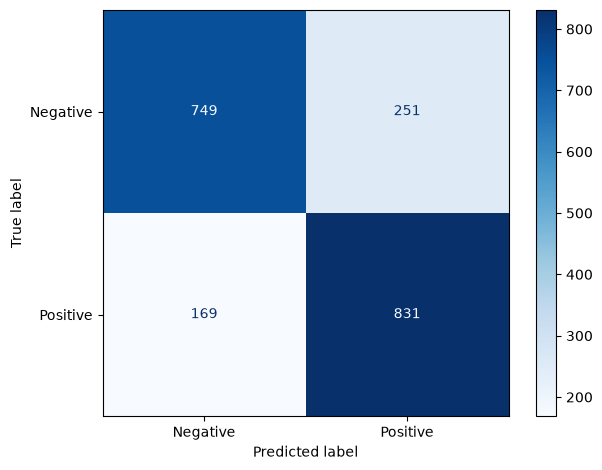

76228

In [12]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    verbose=2,
    callbacks=[early_stopping(patience=2)],
)
loss, accuracy = model.evaluate(test_ds, verbose=0)
probabilities = model.predict(test_ds, verbose=0).ravel()
predictions = (probabilities >= 0.5).astype(int)
print(f'Test loss: {loss:.4f} | Test accuracy: {accuracy:.4f}')
print(
    classification_report(
        test_y,
        predictions,
        target_names=['Negative', 'Positive'],
        digits=4,
        zero_division=0,
    ),
)
ConfusionMatrixDisplay.from_predictions(
    test_y,
    predictions,
    display_labels=['Negative', 'Positive'],
    cmap='Blues',
)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'confusion_matrix.png', dpi=150)
plt.show()
model.save(OUTPUT_DIR / 'imdb_bilstm.keras')
pd.DataFrame(history.history).to_csv(OUTPUT_DIR / 'history.csv', index=False)
pd.DataFrame({'Loss': [loss], 'Accuracy': [accuracy]}).to_csv(
    OUTPUT_DIR / 'metrics.csv',
    index=False,
)
(OUTPUT_DIR / 'vocabulary.txt').write_text('\n'.join(vectorizer.get_vocabulary()))


In [13]:
def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    for ax, metric in zip(axes, ('accuracy', 'loss')):
        if metric not in history.history:
            ax.axis('off')
            continue
        epochs = np.arange(1, len(history.history[metric]) + 1)
        ax.plot(epochs, history.history[metric], label='Train')
        ax.plot(epochs, history.history['val_' + metric], label='Validation')
        ax.set(title=f'{title}: {metric}', xlabel='Epoch', ylabel=metric.title())
        ax.legend()
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{title.lower().replace(' ', '_')}_curves.png", dpi=150)
    plt.show()


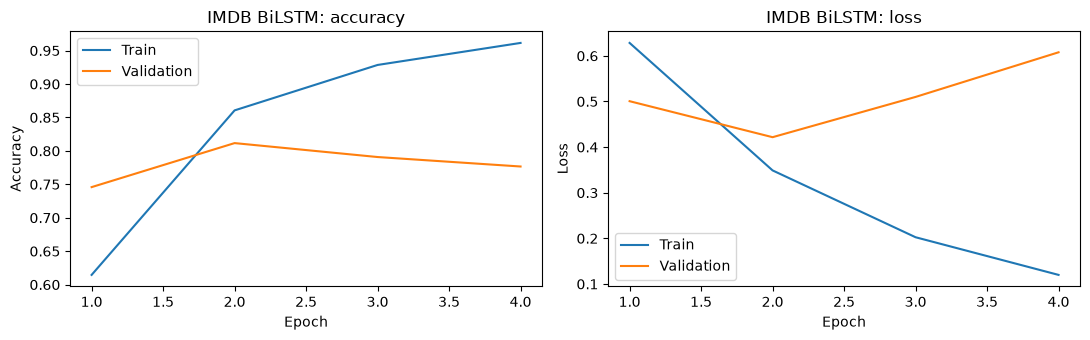

In [14]:
plot_history(history, 'IMDB BiLSTM')


In [15]:
def predict_sentiment(reviews):
    if isinstance(reviews, str):
        reviews = [reviews]
    scores = model.predict(tf.constant(reviews), verbose=0).ravel()
    sentiments = []
    for score in scores:
        if score > 0.6:
            sentiment = 'Positive'
        elif score < 0.4:
            sentiment = 'Negative'
        else:
            sentiment = 'Neutral (uncertain)'
        sentiments.append(sentiment)
    return pd.DataFrame(
        {
            'Review': reviews,
            'Positive probability': scores,
            'Sentiment': sentiments,
        },
    )


In [16]:
index = int(np.random.default_rng(SEED).integers(len(test_y)))
print(
    'Actual label for random test review:',
    'Positive' if test_y[index] else 'Negative',
)
display(predict_sentiment(str(test_text[index])))
display(
    predict_sentiment(
        [
            (
                'This movie was fantastic, the acting was brilliant and I loved '
                'every minute.'
            ),
            'Terrible film. Boring plot, awful acting, a complete waste of time.',
            'The movie was okay, some good parts and some bad parts.',
        ],
    ),
)


Actual label for random test review: Positive


,Review,Positive probability,Sentiment
0,first let me say that i find films like shawsh...,0.777139,Positive


,Review,Positive probability,Sentiment
0,"This movie was fantastic, the acting was brill...",0.938195,Positive
1,"Terrible film. Boring plot, awful acting, a co...",0.016078,Negative
2,"The movie was okay, some good parts and some b...",0.280896,Negative
